# A1 — Teleport a Qubit

Vivekananda GN

Alice holds a qubit in a secret state. She cannot copy it and cannot measure it without destroying it. Yet using one *entangled pair* and two ordinary classical bits, Bob ends up with the exact same state.


**Real use:** moving quantum data between quantum processors (the "quantum internet", distributed quantum ML).

In [ ]:
# Run once (Google Colab or local). Qibo = open-source quantum simulator (qibo.science)
!pip install -q qibo scikit-learn matplotlib scipy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.5/369.5 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 347.2/347.2 kB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 541.5/541.5 kB 33.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 37.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 23.7 MB/s eta 0:00:00


In [ ]:
import numpy as np, matplotlib.pyplot as plt
from qibo import Circuit, gates, set_backend
set_backend("numpy")
np.set_printoptions(precision=3, suppress=True)

[Qibo 0.3.5|INFO|2026-10-03 04:01:37]: Using numpy backend on /CPU:0
INFO:qibo.config:Using numpy backend on /CPU:0


## 1. Build the teleportation circuit
Qubit 0 = Alice's secret. Qubits 1 and 2 = an entangled pair shared by Alice (1) and Bob (2).

In [ ]:
def teleport(theta, phi, corrections=True):
    c = Circuit(3)
    c.add(gates.RY(0, theta)); c.add(gates.RZ(0, phi))      # Alice's secret state (any point on the Bloch sphere)
    c.add(gates.H(1)); c.add(gates.CNOT(1, 2))              # create the entangled pair
    c.add(gates.CNOT(0, 1)); c.add(gates.H(0))              # Alice "mixes" her secret with her half of the pair
    if corrections:                                         # the 2 classical bits tell Bob how to fix his qubit
        c.add(gates.CNOT(1, 2)); c.add(gates.CZ(0, 2))
    return c
teleport(0.9, 0.4).draw()

0: ─RY─RZ───o─H───o─
1: ─H─────o─X───o─|─
2: ───────X─────X─Z─


### Why $0.9$ and $0.4$?
These parameters represent standard spherical coordinates $(\theta, \phi)$ on the **Bloch sphere**:
- $\theta = 0.9$ (in radians) controls the latitude (polar angle), shifting the state from $|0\rangle$ towards $|1\rangle$.
- $\phi = 0.4$ (in radians) controls the longitude (azimuthal angle), adding a relative quantum phase.

Any combination of $\theta \in [0, \pi]$ and $\phi \in [0, 2\pi]$ represents a unique, valid single-qubit quantum state.

## 2. Check: how close is Bob's qubit to Alice's secret? (1.0 = perfect copy)

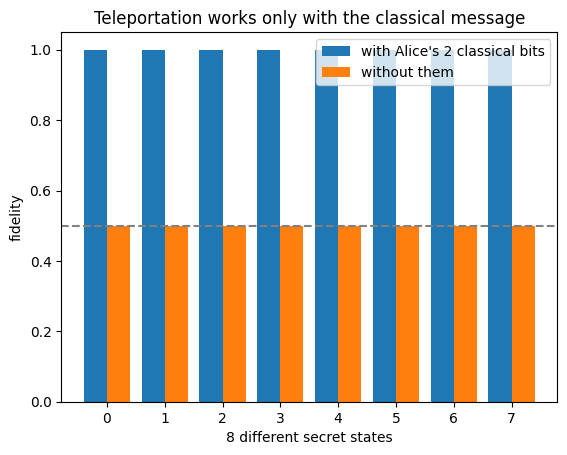

average fidelity WITH classical bits   : 1.0
average fidelity WITHOUT classical bits: 0.5 (= random guess)


In [ ]:
def fidelity(circuit, theta, phi):
    psi = np.array(circuit().state()).reshape(4, 2)          # (Alice's 2 qubits) x (Bob's qubit)
    rho_bob = psi.T @ psi.conj()                             # Bob's qubit on its own
    t = Circuit(1); t.add(gates.RY(0, theta)); t.add(gates.RZ(0, phi)); target = np.array(t().state())
    return float(np.real(target.conj() @ rho_bob @ target))

rng = np.random.default_rng(1)
secrets = [(rng.uniform(0, np.pi), rng.uniform(0, 2*np.pi)) for _ in range(8)]
with_fix = [fidelity(teleport(a, b, True),  a, b) for a, b in secrets]
no_fix   = [fidelity(teleport(a, b, False), a, b) for a, b in secrets]
x = np.arange(8)
plt.bar(x-0.2, with_fix, 0.4, label='with Alice\'s 2 classical bits'); plt.bar(x+0.2, no_fix, 0.4, label='without them')
plt.axhline(0.5, ls='--', c='gray'); plt.xlabel('8 different secret states'); plt.ylabel('fidelity'); plt.legend(); plt.title('Teleportation works only with the classical message'); plt.show()
print("average fidelity WITH classical bits   :", round(np.mean(with_fix), 3))
print("average fidelity WITHOUT classical bits:", round(np.mean(no_fix), 3), "(= random guess)")

## 3. Observations
* The quantum state is **not copied** (no-cloning); it is **moved**: Alice's original is destroyed.
* Nothing travels faster than light: without Alice's two classical bits, Bob's qubit is useless (bars at 0.5).
* Link to ML: large quantum models may need several quantum chips to share quantum data. Teleportation is the building block.


**Try:** change the secret angles; try `corrections=False` and watch the fidelity collapse.